# From Classical ML to Deep Learning: Predicting Diamond Cut Quality

In this notebook we'll:
1. Clean and prepare the diamonds dataset
2. Establish a **classical ML baseline** using Logistic Regression
3. Build a **neural network** with Keras
4. Fix overfitting with **early stopping**
5. Compare training curves to understand *why* early stopping matters

Our target: predicting diamond **cut quality** from its physical and price attributes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
df = pd.read_csv('/kaggle/input/datasets/nancyalaswad90/diamonds-prices/Diamonds Prices2022.csv', index_col=0)

# Basic cleaning steps
# There are 149 duplicates so we will remove them first
df = df.drop_duplicates()

# We will use Ordinal Encoder which is a way to encode multiple columns at the
# same time and also control the labeling. (LabelEncoder will encode alphabetically)
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
color_order = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

# Ordinal encode color and clarity only
encoder = OrdinalEncoder(categories=[color_order, clarity_order, cut_order])
df[['color', 'clarity', 'cut']] = encoder.fit_transform(df[['color', 'clarity', 'cut']])

df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,4.0,5.0,1.0,61.5,55.0,326,3.95,3.98,2.43
2,0.21,3.0,5.0,2.0,59.8,61.0,326,3.89,3.84,2.31
3,0.23,1.0,5.0,4.0,56.9,65.0,327,4.05,4.07,2.31
4,0.29,3.0,1.0,3.0,62.4,58.0,334,4.20,4.23,2.63
5,0.31,1.0,0.0,1.0,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.describe()

,carat,cut,color,clarity,depth,table,price,x,y,z
count,53794.00000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000
mean,0.79778,2.904134,3.406086,3.051920,61.748080,57.458109,3933.065082,5.731214,5.734653,3.538714
std,0.47339,1.116098,1.701117,1.646857,1.429909,2.233679,3988.114460,1.120695,1.141209,0.705037
min,0.20000,0.000000,0.000000,0.000000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.40000,2.000000,2.000000,2.000000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.70000,3.000000,3.000000,3.000000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.04000,4.000000,5.000000,4.000000,62.500000,59.000000,5326.750000,6.540000,6.540000,4.030000
max,5.01000,4.000000,6.000000,7.000000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


# **Features Scaling**

We usually scale features before training machine learning models because raw features can have very different ranges and units, which may cause problems.

For example, in the Diamonds dataset:

* `Carat` ranges from about 0.2–5.01 carats

* `Price` ranges from about 326–18823 dollars

Without scaling, algorithms that rely on distances or weights may treat `Price` as more important than `Carat` simply because the numbers are larger.

Standardization solves this by transforming each feature. We don't need to do that with the target labels, only the features.

In [4]:
X = df.drop(columns=['cut'])
y = df['cut'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y 
    #stratify y ensures that each class
    #is proportionally represented in both train and test
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (43035, 9), Test: (10759, 9)


## 1. Classical ML Baseline: Logistic Regression

Before reaching for deep learning, let's see what a simple machine learning model can do. This gives us a benchmark. If a neural network can't beat it, it isn't worth the added complexity.

### A quick note on multi-class classification

So far you may have seen classification framed as a **binary** problem, i.e predicting one of two classes (spam vs. not spam, ideal vs. not ideal).
Here, we will use `cut`'s **five** possible classes: `Fair`, `Good`, `Very Good`,
`Premium`, `Ideal`. This is a **multi-class classification** problem.

A few things change under the hood when moving from binary to multi-class:

- **Logistic Regression** handles this via a **multinomial** formulation:
  instead of one decision boundary separating two classes, it learns a
  set of coefficients for *each* class and uses the **softmax** function
  to turn raw scores into a probability distribution across all classes
  (probabilities across all 5 classes sum to 1). `LogisticRegression` already handles this when the target has more than 2 values.
- **Neural networks** handle it the same way at the output layer: our
  final `Dense` layer will have **5 units** (one per class) with a
  **softmax** activation.
- **Evaluation** also changes: instead of a single precision/recall/F1 for
  "the positive class," `classification_report` will show precision,
  recall, and F1 **per class**, plus averages across all of them.

Keep an eye on whether performance is roughly even across all five
`cut` categories, or whether the model struggles with some (e.g. classes
with fewer training examples, like `Fair`).

In [5]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

print("Logistic Regression — Classification Report (Test Set)")
print(classification_report(y_test, y_pred_lr, target_names=cut_order))

Logistic Regression — Classification Report (Test Set)
              precision    recall  f1-score   support

        Fair       0.81      0.49      0.61       319
        Good       0.60      0.15      0.24       978
   Very Good       0.50      0.41      0.45      2414
     Premium       0.65      0.71      0.68      2750
       Ideal       0.71      0.88      0.79      4298

    accuracy                           0.65     10759
   macro avg       0.65      0.53      0.55     10759
weighted avg       0.64      0.65      0.63     10759



## 2. Introducing Neural Networks

Logistic regression learned one linear equation per class. A **neural
network** stacks multiple layers of these linear transformations, each
followed by a non-linear **activation function**, letting it learn more
complex patterns than a single linear model can.

Our layers will consist of:
1. **Input Layer** -> the scaled Diamond features
2. **Hidden Layers** -> dense hidden layers which compute the weighted sum of all the connected neurons, then apply `relu`.
3. **Output Layer** -> 5 neurons with `softmax` which convert the raw scores into probabilities for the 5 `cut` classes.

In [6]:
# We will be using sparse_categorical_crossentropy since our 
# target Y is in the form of 0,1,2,3 not one hot encoded [0,1,0,0]
def build_model():
    model = keras.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(16, activation='relu'),
        layers.Dense(len(cut_order), activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

Using this predefined function we want to create 2 different neural networks with the same structure, and train them differently to explore the concept of early stopping!

In [7]:
neural_model = build_model()
neural_model_with_es = build_model()

2026-09-22 23:10:25.311164: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Epochs, Batches, and Validation

**Epoch** — one full pass through the training data. `epochs=200` = the
model sees every example 200 times.

**Batch** — training data is fed in small chunks, not all at once.
`batch_size=32` = weights update every 32 examples, until one epoch is
complete.

**Validation set** — a slice of data the model never trains on, used to
check it's actually generalizing (not just memorizing training data).
`validation_split=0.15` sets aside 15% **once**, before training starts:

- Trains on the remaining 85%
- After each epoch, checks itself on the untouched 15% (no learning here)

Result: two scores per epoch — **training** (fitting) vs. **validation**
(generalizing). If train keeps improving while validation stalls or
worsens, the model is starting to memorize rather than learn.

In [8]:
history_nm = neural_model.fit(
    X_train_scaled, y_train,
    validation_split=0.3,
    epochs=200,
    batch_size=32,
    verbose=1
)

Epoch 1/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6505 - loss: 0.9157 - val_accuracy: 0.7026 - val_loss: 0.7814
Epoch 2/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7044 - loss: 0.7714 - val_accuracy: 0.7148 - val_loss: 0.7517
Epoch 3/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7111 - loss: 0.7488 - val_accuracy: 0.7196 - val_loss: 0.7394
Epoch 4/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7153 - loss: 0.7320 - val_accuracy: 0.7250 - val_loss: 0.7267
Epoch 5/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7252 - loss: 0.7106 - val_accuracy: 0.7391 - val_loss: 0.7151
Epoch 6/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7395 - loss: 0.6794 - val_accuracy: 0.7474 - val_loss: 0.7010
Epoch 7/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7527 - loss: 0.6460 - val_accuracy: 0.7530 - val_loss: 0.6892
Epoch 8/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7579 - loss: 0.6244 - val_accu

In [9]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True)

history_nm_es = neural_model_with_es.fit(
    X_train_scaled, y_train,
    validation_split=0.3,
    epochs=200,
    batch_size=32,
    verbose=1,callbacks=[early_stop]
)

Epoch 1/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6411 - loss: 0.9482 - val_accuracy: 0.7053 - val_loss: 0.7848
Epoch 2/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7014 - loss: 0.7760 - val_accuracy: 0.7152 - val_loss: 0.7519
Epoch 3/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7085 - loss: 0.7529 - val_accuracy: 0.7212 - val_loss: 0.7398
Epoch 4/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7119 - loss: 0.7394 - val_accuracy: 0.7246 - val_loss: 0.7311
Epoch 5/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7181 - loss: 0.7246 - val_accuracy: 0.7297 - val_loss: 0.7194
Epoch 6/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7284 - loss: 0.7027 - val_accuracy: 0.7443 - val_loss: 0.7019
Epoch 7/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7433 - loss: 0.6692 - val_accuracy: 0.7565 - val_loss: 0.6891
Epoch 8/200
942/942 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7546 - loss: 0.6394 - val_accu

We didnt complete all epochs! how many did we do?


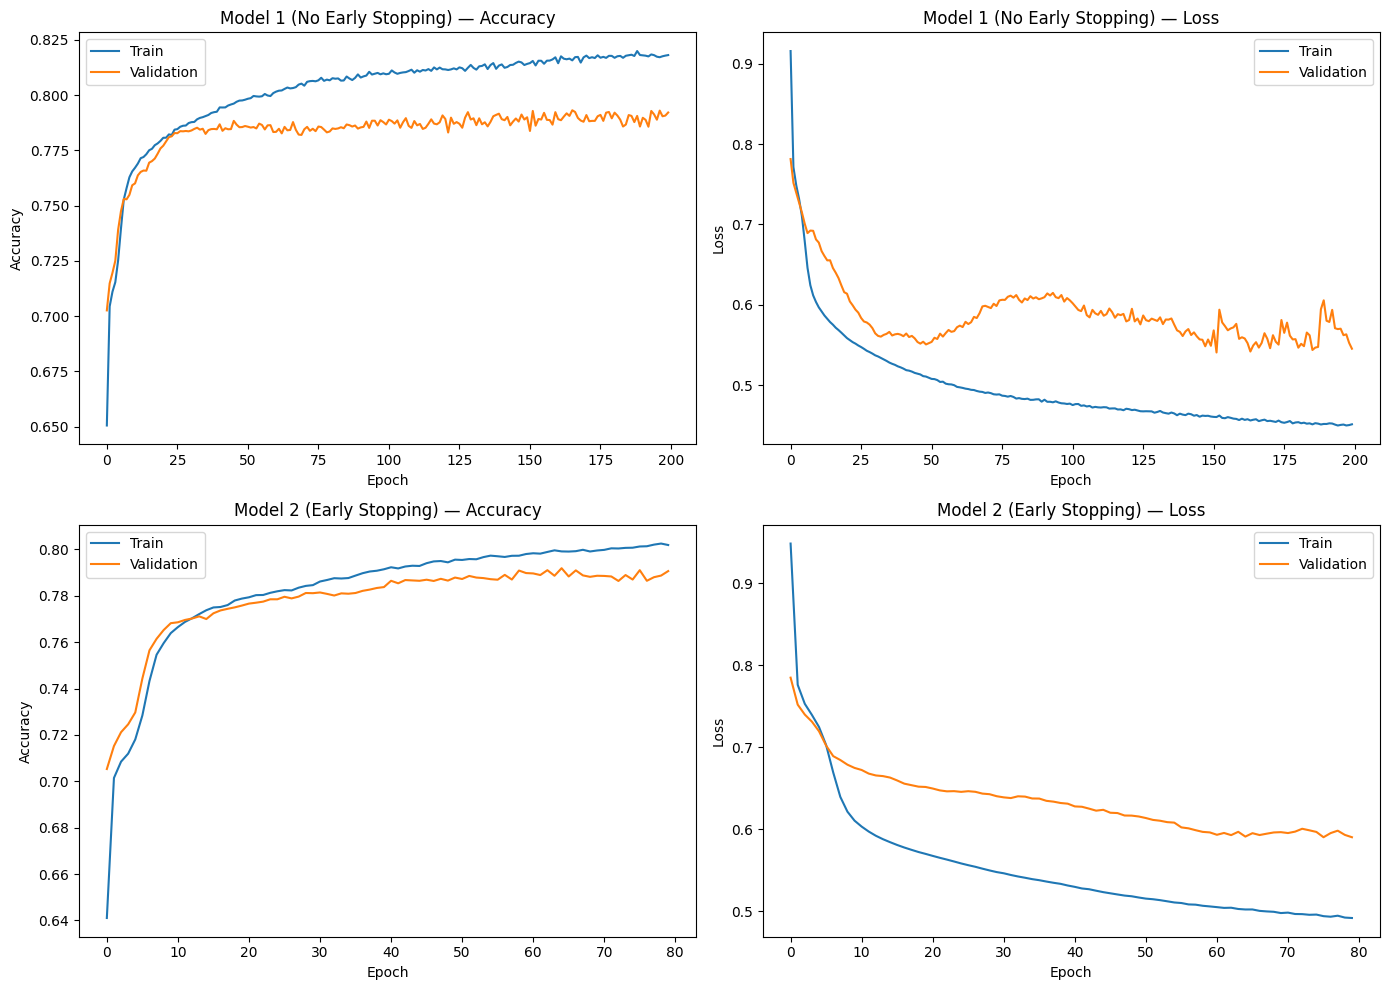

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Accuracy - overfit model
axes[0, 0].plot(history_nm.history['accuracy'], label='Train')
axes[0, 0].plot(history_nm.history['val_accuracy'], label='Validation')
axes[0, 0].set_title('Model 1 (No Early Stopping) — Accuracy')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()

# Loss - overfit model
axes[0, 1].plot(history_nm.history['loss'], label='Train')
axes[0, 1].plot(history_nm.history['val_loss'], label='Validation')
axes[0, 1].set_title('Model 1 (No Early Stopping) — Loss')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()

# Accuracy - early stopped model
axes[1, 0].plot(history_nm_es.history['accuracy'], label='Train')
axes[1, 0].plot(history_nm_es.history['val_accuracy'], label='Validation')
axes[1, 0].set_title('Model 2 (Early Stopping) — Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

# Loss - early stopped model
axes[1, 1].plot(history_nm_es.history['loss'], label='Train')
axes[1, 1].plot(history_nm_es.history['val_loss'], label='Validation')
axes[1, 1].set_title('Model 2 (Early Stopping) — Loss')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Loss')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

#### We can see from the above graphs that not using early stopping causes overfitting! We can tell from the difference between the validation accuracy/loss and the training accuracy/loss. At one point the validation loss starts increasing.

In [11]:
test_loss_overfit, test_acc_overfit = neural_model.evaluate(X_test_scaled, y_test, verbose=0)
test_loss_es, test_acc_es = neural_model_with_es.evaluate(X_test_scaled, y_test, verbose=0)

lr_test_acc = log_reg.score(X_test_scaled, y_test)

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'NN — No Early Stopping', 'NN — Early Stopping'],
    'Test Accuracy': [lr_test_acc, test_acc_overfit, test_acc_es],
    'Test Loss': [np.nan, test_loss_overfit, test_loss_es],
    'Epochs Trained': [np.nan, len(history_nm.history['loss']), len(history_nm_es.history['loss'])]
})
comparison

,Model,Test Accuracy,Test Loss,Epochs Trained
0,Logistic Regression,0.654615,NaN,NaN
1,NN — No Early Stopping,0.796821,0.515400,200.0
2,NN — Early Stopping,0.800074,0.505428,80.0


#### As we can see here early stopping had only a minor improvement to the accuracy, but we saved around ~150 epochs! The minor difference here can be explained by the simplicity of the current dataset, but its only for experimentation purposes.

## Graded Task

Write your code in the cells below!
